# 0 · Data preprocessing

**Run this first.** It builds the data every other notebook uses.

The client generates frames the stream never sent: **2x frame generation**. The host sends
every second frame of the display rate and the client makes the one between. Here it
*interpolates*: it waits for received frame N+2 and draws N+1 from N and N+2, both ends of the
motion known - at the price of showing every frame half a received interval late
(desktop-streamer's client shows the made frame at 0 and N+2 at ½). An example is received
frames N and N+2 as the input and the unsent frame N+1 as the target.

This is `../frame_gen_extra/00_data_preprocess.ipynb` with its output in
`datasets/frame_gen_intra/`: the same sources, scenes, stream, filter and seed, so the same runs
(to the codec's run-to-run difference), and the two problems are scored on the same motion. Only
the sample read out of a run differs: a run's frames 0, 2, 4 and 6 are received, and 1, 3 and 5
lie between two of them.

The set is mostly **real video**, with **drawn scenes** beside it:

- **Screen recordings** (kind `screen`): the YouTube-8M sequences of the computer categories that
  are screen captures - Windows desktops, websites, screencasts, editors, Cinema 4D, Photoshop,
  maps, phone screens, a piano-roll app - picked by eye from a frame of each (`helpers/recorded.py`,
  extrapolation's notebook 11): 91 videos at 24-30 fps and 4 at 50-60 fps, 5 clips of 32 frames
  each. At 24-30 fps the client receives 12-15 fps and makes the real frame between - the same
  task at half the rate, with twice the motion between received frames.
- **Other video** (kind `video`): the YouTube-8M sequences at 50 fps or more that are not screen
  captures - games, sports, nature: the 2x task at 60 fps.
- **Drawn scenes** (kinds `page`, `desktop`, `photo`): a still picture - a drawn desktop screen or a
  DIV2K photo - animated as a desktop in use (`helpers/scenes.py`): a scroll that starts and
  stops, a region scrolling inside a window, a window dragged, a menu popping up. About a third of
  the sources. Each scene is read **from a random phase**, so a stop or a menu lands on the frame
  to make as often as on a received one - read from its first frame, every change would land on
  a received frame and N+1 would always lie exactly half way, which a real screen does not promise.

Every clip keeps its own frame rate, so every score can be split by it.

**Recordings repeat frames**: a recorder that captures slower than its video's rate fills the gap
by showing a frame twice, and then N+1 is a copy of N or of N+2 - holding that frame exact by
construction. A live capture does not. So each recording keeps the mean |luma change| between its
consecutive source frames (`steps`), and a received frame N makes a sample only where the frames
from N-2 to N+2 all change, or none does (`runs.valid`): the content moves and every frame is
new, or the content holds still.

This notebook:

1. **Collects** the sources and splits them - recordings **by video** (a third of each category's
   videos to validation), pictures by their datasets' own lists.
2. **Streams** each clip the way the host does (`helpers/degrade.py`): shrink it, then compress it
   with H.264. The client works from the frames it *decoded*, and the target is a decoded frame
   too. The whole clip is encoded and the received frames are every second of it.
3. **Cuts** runs out of each clip: one spot of the screen, held still for `FRAMES_PER_RUN` frames
   from a received one, with a wide **halo** of context around it - for a recording, only where
   all of its samples are valid. Most of a screen holds still, so most still spots are dropped.
4. **Saves** the runs as one `.npy` array per split plus a `manifest.json` in
   `datasets/frame_gen_intra/`.

Train and validation are split by *source* - for a recording, by its whole video - never by run:
runs of one clip overlap in time and in content.

In [1]:
"""Settings."""

from helpers import recorded, sources

CAPTURE_DIR = sources.RAW / "captures"        # your own screenshots
OUT_DIR = sources.ROOT / "frame_gen_intra"    # where the runs are written
SYNTHETIC_DIR = OUT_DIR / "synthetic"         # drawn desktop frames

SCALE = 2                  # the stream's downscale: 1280x720 on the host is 640x360 in the stream
CORE = 64                  # the spot a run is scored on, in stream pixels
HALO = 16                  # context per side; the client's tile has 4, notebooks cut down to it
FRAMES_PER_RUN = 8         # consecutive display frames per run, starting on a received one:
                           # received 0, 2, 4, 6 - and 1, 3, 5 between two of them to be made
RECEIVED_EVERY = 2         # the stream sends every 2nd display frame: 2x frame generation
RUNS_PER_SOURCE = 16       # runs cut from each source
CURSOR_RUNS = 2            # of those, cut around the cursor when the clip has one
CROP_TRIES = 8             # attempts per run before a still source gives up
VAR_MIN = 24.0             # skip runs whose brightness varies less than this (flat areas)
STILL_KEEP = 0.2           # share of the runs where nothing moves that are kept anyway
VAL_FRACTION = 0.2         # share of your own captures kept for validation
SEED = 0

# Recordings: the screen captures (helpers/recorded.py, any rate from 24 fps) and the other
# YouTube-8M sequences at MIN_VIDEO_FPS or more, split by video - REAL_VAL_SHARE of each
# category's videos to validation.
VIDEO_DATASET = "yt8m-videos"
MIN_VIDEO_FPS = 50
MIN_SCREEN_FPS = 24
REAL_VAL_SHARE = 1 / 3

# Drawn scenes: how many pictures of each dataset to animate, "train" from its train.txt and
# "val" from its test.txt - about a third of the sources, beside the recordings.
DATASETS = {
    "screens": {"train": 200, "val": 40},   # desktop screens, drawn by datasets/screens.py
    "div2k": {"train": 60, "val": 15},
}

# A still picture becomes a 1 second clip of a 1280x720 window at the display rate, animated
# by helpers/scenes.py.
IMAGE_FPS = 60
CLIP_FRAMES = 60
WINDOW = (1280, 720)
# desktop-streamer's capture is told not to draw the pointer, and the client draws it itself,
# so the frames a model sees have none. True draws an arrow into them, as a capture with the
# pointer on would.
DRAW_CURSOR = False

# "stream": each source gets a random filter, bitrate and loop filter (and no codec for
# CLEAN_SHARE of them), as in ../upscale. "clean": a plain bicubic downscale, no codec.
DEGRADATION = "stream"
CLEAN_SHARE = 0.1
DEBLOCK_SHARE = 0.5

# Drawn desktop frames: only trained on when there is no other data.
SYNTHESISE_IF_EMPTY = True
SYNTHETIC_FRAMES = 12
SYNTHETIC_SIZE = (960, 600)

INPUT = CORE + 2 * HALO
assert CLIP_FRAMES >= FRAMES_PER_RUN

In [2]:
"""Imports and folders."""

import json
import subprocess
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

from helpers import degrade, runs, scenes

IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
rng = np.random.default_rng(SEED)

# how datasets/screens.py drew each screen: a "page" or a "desktop", and its display scale
SCREENS_JSON = sources.RAW / "screens" / "screens.json"
SCREENS = ({entry["file"]: entry for entry in json.loads(SCREENS_JSON.read_text(encoding="utf-8"))}
           if SCREENS_JSON.exists() else {})

CAPTURE_DIR.mkdir(parents=True, exist_ok=True)
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
print("datasets ", sources.ROOT)
print("output   ", OUT_DIR)

datasets  /mnt/d/datasets
output    /mnt/d/datasets/frame_gen_intra


## 1. Collect sources

Download the datasets with:

```
uv run datasets/screens.py
uv run datasets/download.py yt8m-videos --total 1000 --sequences 5
uv run datasets/download.py div2k
```

You can also put screenshots in `datasets/raw/captures/`; they are animated like the drawn
screens.

The recordings are the core of the set: what a screen really does between two frames. Of the
YouTube-8M computer categories (`datasets/yt8m-mix.txt`) only the videos that are screen captures
are kept as `screen` - the categories also hold filmed monitors, people talking and kitchen
blenders - and the other sequences at 50 fps or more are `video`. The drawn screens and photos
bring long scrolls, drags and pans over text and pictures, with what moved recorded.

In [3]:
"""Draw a fake desktop frame: windows with title bars, text-like lines, and a noisy block."""

def synthesise_frame(size, rng):
    width, height = size
    background = tuple(int(v) for v in rng.integers(20, 60, size=3))
    frame = Image.new("RGB", size, background)
    draw = ImageDraw.Draw(frame)

    for y in range(height):  # wallpaper gradient
        shade = int(18 * y / height)
        draw.line([(0, y), (width, y)], fill=tuple(min(255, c + shade) for c in background))

    for _ in range(int(rng.integers(2, 5))):  # windows
        w = int(rng.integers(width // 4, width // 2))
        h = int(rng.integers(height // 4, height // 2))
        x = int(rng.integers(0, max(1, width - w)))
        y = int(rng.integers(0, max(1, height - h)))
        panel = tuple(int(v) for v in rng.integers(180, 250, size=3))
        accent = tuple(int(v) for v in rng.integers(40, 140, size=3))
        draw.rectangle([x, y, x + w, y + h], fill=panel, outline=accent, width=2)
        draw.rectangle([x, y, x + w, y + 22], fill=accent)  # title bar
        for i in range(3):  # window buttons
            draw.ellipse([x + w - 18 - i * 16, y + 6, x + w - 8 - i * 16, y + 16], fill=panel)

        ink = tuple(int(v) for v in rng.integers(0, 90, size=3))
        row = y + 34
        while row < y + h - 12:  # text-like lines
            length = int(rng.integers(w // 4, max(w // 4 + 1, w - 24)))
            draw.rectangle([x + 12, row, x + 12 + length, row + 4], fill=ink)
            row += int(rng.integers(10, 18))

    # a block of noise stands in for a video playing on screen
    nw, nh = width // 5, height // 5
    nx, ny = int(rng.integers(0, width - nw)), int(rng.integers(0, height - nh))
    frame.paste(Image.fromarray(rng.integers(0, 255, (nh, nw, 3), dtype=np.uint8)), (nx, ny))
    return frame

In [4]:
"""List every source: where it is, its split, and what it is."""


def video_fps(path, cache={}):
    """A sequence's frame rate - probed once per video, whose sequences share it."""
    folder = path.parent
    if folder not in cache:
        out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                              "stream=avg_frame_rate", "-of", "csv=p=0", str(path)],
                             capture_output=True, text=True).stdout.strip()
        numerator, _, denominator = out.partition("/")
        cache[folder] = float(numerator) / float(denominator or 1) if numerator else 0.0
    return cache[folder]


items = []
# drawn scenes: pictures, split by their datasets' own lists
for name, wanted in DATASETS.items():
    for split, count in wanted.items():
        try:
            paths = sources.files(name, "test" if split == "val" else "train")
        except FileNotFoundError as error:
            print(f"  {name}: not on disk, skipped ({error})")
            break
        if count is not None and count < len(paths):
            paths = [paths[i] for i in sorted(rng.choice(len(paths), count, replace=False))]
        items += [{"dataset": name, "split": split, "path": p, "kind": "image"} for p in paths]

# recordings: every sequence of the YouTube-8M set, train and test lists alike, split here by video
try:
    listed = sources.files(VIDEO_DATASET, "train") + sources.files(VIDEO_DATASET, "test")
except FileNotFoundError as error:
    listed = []
    print(f"  {VIDEO_DATASET}: not on disk, skipped ({error})")
by_video = {}
for path in listed:
    by_video.setdefault(path.parent.relative_to(sources.RAW / VIDEO_DATASET).as_posix(), []).append(path)
screens = [v for v in recorded.SCREENS if v in by_video and video_fps(by_video[v][0]) >= MIN_SCREEN_FPS]
others = sorted(v for v in by_video if v not in recorded.SCREENS and video_fps(by_video[v][0]) >= MIN_VIDEO_FPS)
held = set(recorded.split_by_video(screens, REAL_VAL_SHARE, SEED)[0]) | set(recorded.split_by_video(others, REAL_VAL_SHARE, SEED)[0])
for kind, videos in (("screen", screens), ("video", others)):
    for video in videos:
        items += [{"dataset": VIDEO_DATASET, "split": "val" if video in held else "train", "path": p, "kind": kind,
                   "video": video} for p in sorted(by_video[video])]
    rates = Counter(round(video_fps(by_video[v][0])) for v in videos)
    print(f"  {kind}: {len(videos)} videos ({sum(v in held for v in videos)} to validation), rates {dict(sorted(rates.items()))}")

# The drawn frames use their own random generator, so drawing them does not change any
# other random choice in this notebook.
synthetic = sorted(SYNTHETIC_DIR.glob("synthetic_*.png"))
if len(synthetic) < SYNTHETIC_FRAMES:
    synthetic_rng = np.random.default_rng(SEED)
    synthetic = [SYNTHETIC_DIR / f"synthetic_{i:04d}.png" for i in range(SYNTHETIC_FRAMES)]
    for path in synthetic:
        synthesise_frame(SYNTHETIC_SIZE, synthetic_rng).save(path)

# Your captures, split here. With no datasets and no captures, the drawn frames instead.
own = sorted(p for p in CAPTURE_DIR.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES)
label = "captures"
if not own and not items and SYNTHESISE_IF_EMPTY:
    print(f"no datasets and no captures - training on the {len(synthetic)} drawn frames")
    own, label = synthetic, "synthetic"
order = rng.permutation(len(own))
n_val = max(1, round(len(own) * VAL_FRACTION)) if len(own) > 1 else 0
held_out = {own[i] for i in order[:n_val]}
items += [{"dataset": label, "split": "val" if p in held_out else "train", "path": p, "kind": "image"}
          for p in own]

if not items:
    raise RuntimeError(f"no datasets, no images in {CAPTURE_DIR}, and synthesis is off")

for split in ("train", "val"):
    counts = Counter(item["kind"] if item["kind"] != "image" else item["dataset"] for item in items if item["split"] == split)
    print(f"{split:5} {sum(counts.values()):4} sources  {dict(counts)}")

  screen: 93 videos (31 to validation), rates {24: 3, 25: 14, 29: 1, 30: 71, 50: 1, 60: 3}
  video: 49 videos (11 to validation), rates {50: 10, 60: 39}
train  760 sources  {'screens': 200, 'div2k': 60, 'screen': 310, 'video': 190}
val    265 sources  {'screens': 40, 'div2k': 15, 'screen': 155, 'video': 55}


## 2. Animate and stream

Each source becomes a clip. A recording already is one, at its own rate. A still picture becomes
`CLIP_FRAMES` frames at `IMAGE_FPS` of a desktop being used (`scenes.sample`), drawn from what kind
of picture it is:

| kind | background | region scroll | drag | menu | cursor |
| --- | --- | --- | --- | --- | --- |
| page (a tall screen) | still, wheel, flick or steady scroll, vertical | - | 10% | 20% | 80% |
| desktop (a whole screen, your captures) | still | 40% | 35% | 30% | 90% |
| photo | still, flick or steady pan, any way | - | 10% | 10% | 50% |

The **whole frame** then goes through the stream (shrink, 4:2:0 colour, H.264, decode), not each
run on its own. Each source gets its own random settings (`degrade.sample`), and they, the scene
(drawn) or the frame steps (recorded) are written to the manifest, so results can later be split
by bitrate, by what moved, or by frame rate. A run of `FRAMES_PER_RUN` frames is kept from each
clip, starting on a received frame - for a recording, at a place where all its samples are valid:
the frames around each of its received frames N all change, or none does.

In [5]:
"""Make one source a clip, send it through the stream, keep a run of frames."""

def degradation_for(fps):
    if DEGRADATION == "clean":
        return degrade.Degradation(scale=SCALE, filter="bicubic", bpp=None, fps=fps)
    return degrade.sample(rng, scale=SCALE, fps=round(fps), clean=CLEAN_SHARE, deblock=DEBLOCK_SHARE)


def screen_of(item):
    """How datasets/screens.py drew a screen, or {} for anything else."""
    if item["dataset"] != "screens":
        return {}
    return SCREENS.get(item["path"].relative_to(sources.RAW / "screens").as_posix(), {})


def kind_of(item):
    """What a source is: "screen" or "video" (recorded), or to `scenes` "page", "desktop" or "photo"."""
    if item["kind"] in ("screen", "video"):
        return item["kind"]
    if item["dataset"] == "screens":
        return screen_of(item).get("kind", "desktop")
    return "desktop" if item["dataset"] in ("captures", "synthetic") else "photo"


def run_offsets(record, count):
    """The first frames of every run whose samples are all valid (`runs.valid`), of a clip of `count` frames."""
    starts = range(0, count - FRAMES_PER_RUN + 1, RECEIVED_EVERY)
    return [o for o in starts if all(runs.valid(record, n, RECEIVED_EVERY)
                                     for n in range(o + RECEIVED_EVERY, o + FRAMES_PER_RUN, RECEIVED_EVERY))]


def clip_of(item):
    """The decoded stream frames (FRAMES_PER_RUN, h, w, 3) of one source, the cursor's tip on
    each of them in stream pixels (None without one), and how they were made - or None where a
    recording has no run whose samples are all valid."""
    kind = kind_of(item)
    record, cursor = {"kind": kind}, None
    if kind in ("screen", "video"):
        frames, fps = sources.load_sequence(item["path"])
        record.update(video=item["video"], steps=runs.raw_steps(frames))
    else:
        image = sources.load_image(item["path"])
        scene = scenes.sample(rng, (image.shape[1], image.shape[0]), kind, CLIP_FRAMES, WINDOW,
                              cursor_scale=screen_of(item).get("scale"), fps=IMAGE_FPS)
        frames, fps = scenes.render(image, scene, cursor=DRAW_CURSOR), IMAGE_FPS
        record.update(events=scene.events(), scene=scene.as_dict())
        if scene.cursor is not None:
            cursor = np.array(scene.cursor) / SCALE
    if len(frames) < FRAMES_PER_RUN:
        raise ValueError(f"{item['path']}: only {len(frames)} frames")
    offsets = run_offsets(record, len(frames))
    if not offsets:
        return None

    d = degradation_for(fps)
    _, stream = degrade.degrade(frames, d)
    # a received frame first: the stream sends frames 0, RECEIVED_EVERY, 2 * RECEIVED_EVERY...
    offset = int(rng.choice(offsets))
    record.update(degradation=d.as_dict(), offset=offset, fps=fps)
    keep = slice(offset, offset + FRAMES_PER_RUN)
    return stream[keep], None if cursor is None else cursor[keep], record


demo = next((item for item in items if kind_of(item) == "screen"), items[0])
made = clip_of(demo)
while made is None:
    demo = next(item for item in items if kind_of(item) == "screen" and item["path"] != demo["path"] and item["path"] > demo["path"])
    made = clip_of(demo)
stream_demo, cursor_demo, demo_record = made
print(demo["dataset"], demo["path"].relative_to(sources.RAW / demo["dataset"]), "-", demo_record["kind"])
print("stream", stream_demo.shape)
print({key: value for key, value in demo_record.items() if key not in ("scene", "steps")})

yt8m-videos Cinema_4D/3N2nRlKlbgk/03.mkv - screen
stream (8, 360, 640, 3)
{'kind': 'screen', 'video': 'Cinema_4D/3N2nRlKlbgk', 'degradation': {'scale': 2, 'filter': 'area', 'bpp': 0.5155728546429743, 'fps': 25, 'deblock': True}, 'offset': 4, 'fps': 25.0}


## 3. Cut runs

A run is one spot of the stream, held still for `FRAMES_PER_RUN` frames while the content
moves under it - exactly what one tile sees.

- The run is `INPUT` pixels: the `CORE` that is scored plus `HALO` pixels of context per
  side. The client's tile has a halo of 4; 16 are stored so a notebook can measure what
  more context is worth before anyone changes the client.
- Spots start on even pixels, because 4:2:0 colour is shared between pixel pairs.
- `CURSOR_RUNS` spots are placed around the pointer (its tip somewhere in the core on the
  run's middle frame) and kept whatever they show: it is where a window is dragged and a menu
  opens, a few pixels out of a frame of 230,000 that a random spot would almost never hold -
  whether or not the pointer is drawn (`DRAW_CURSOR`).
- Every other spot is dropped if it is flat (brightness variance under `VAR_MIN`), and
  kept if something in its core changes between two of its frames (`runs.changed_share`:
  more than `runs.MOVING_SHARE` of the core's pixels move by more than
  `runs.CHANGED_LEVEL` in luma). A spot where nothing moves is kept only `STILL_KEEP` of the
  time: repeating the last frame is already perfect there, and a whole set of them would
  teach a model nothing else.

In [6]:
"""Cut runs at random places of one clip, and around its cursor."""

LUMA = runs.LUMA


def core(run):
    return run[:, HALO:HALO + CORE, HALO:HALO + CORE]


def moves(run):
    """Whether anything in the run's core changes between two of its frames."""
    return runs.changed_share(core(run)[1:], core(run)[:-1]).max() >= runs.MOVING_SHARE


def even(value, highest):
    return int(np.clip(2 * round(value / 2), 0, highest // 2 * 2))


def crops(stream, cursor, rng):
    """[(run (T, INPUT, INPUT, 3), (y, x, tag)), ...] of one clip - tag "cursor", "moving" or
    "still" - and how many spots were skipped."""
    skipped = {"flat": 0, "still": 0}
    height, width = stream.shape[1:3]
    if height < INPUT or width < INPUT:
        return [], skipped
    spots = []
    if cursor is not None:
        # the tip somewhere in the core on the middle frame, leaving room for the arrow below it
        tip_x, tip_y = cursor[len(cursor) // 2]
        for _ in range(CURSOR_RUNS):
            y = even(tip_y - HALO - rng.uniform(4, CORE - 20), height - INPUT)
            x = even(tip_x - HALO - rng.uniform(4, CORE - 16), width - INPUT)
            spots.append((stream[:, y:y + INPUT, x:x + INPUT].copy(), (y, x, "cursor")))
    for _ in range(RUNS_PER_SOURCE * CROP_TRIES):
        if len(spots) == RUNS_PER_SOURCE:
            break
        y = 2 * int(rng.integers(0, (height - INPUT) // 2 + 1))
        x = 2 * int(rng.integers(0, (width - INPUT) // 2 + 1))
        run = stream[:, y:y + INPUT, x:x + INPUT]
        if (core(run).astype(np.float32) @ LUMA).var(axis=(1, 2)).mean() < VAR_MIN:
            skipped["flat"] += 1
            continue
        tag = "moving" if moves(run) else "still"
        if tag == "still" and rng.random() >= STILL_KEEP:
            skipped["still"] += 1
            continue
        # .copy() so a kept run does not keep the whole clip in memory
        spots.append((run.copy(), (y, x, tag)))
    return spots, skipped


spots, skipped = crops(stream_demo, cursor_demo, rng)
tags = [tag for _, (_, _, tag) in spots]
print(f"{demo['path'].name}: {len(spots)} runs kept {dict(Counter(tags))}, "
      f"spots skipped {skipped}")

03.mkv: 16 runs kept {'still': 16}, spots skipped {'flat': 11, 'still': 56}


In [7]:
"""Process every source and collect the runs per split."""

buckets = {split: {"frames": [], "files": [], "sources": []} for split in ("train", "val")}
skipped_spots = {"flat": 0, "still": 0}
no_valid_run = Counter()

start = time.time()
for n, item in enumerate(items, 1):
    bucket = buckets[item["split"]]
    made = clip_of(item)
    if made is None:
        no_valid_run[kind_of(item)] += 1
        continue
    stream, cursor, record = made
    base = {"captures": CAPTURE_DIR, "synthetic": SYNTHETIC_DIR}.get(item["dataset"], sources.RAW / item["dataset"])
    name = item["path"].relative_to(base).as_posix()
    spots, skipped = crops(stream, cursor, rng)
    for reason, count in skipped.items():
        skipped_spots[reason] += count
    if not spots:
        print(f"  skipped {item['dataset']}/{name} - too flat")
        continue
    first = len(bucket["frames"])
    bucket["frames"].extend(run for run, _ in spots)
    bucket["files"].append(f"{item['dataset']}/{name}")
    # runs [first, last) of this split came from this source, at these spots, made this way
    bucket["sources"].append({"dataset": item["dataset"], "file": name, "runs": [first, len(bucket["frames"])],
                              "spots": [list(spot) for _, spot in spots], **record})
    if n % 100 == 0:
        print(f"  {n}/{len(items)} sources, {time.time() - start:.0f}s")

for split, bucket in buckets.items():
    bucket["frames"] = (np.stack(bucket["frames"]) if bucket["frames"]
                        else np.empty((0, FRAMES_PER_RUN, INPUT, INPUT, 3), np.uint8))
    tags = [spot[2] for source in bucket["sources"] for spot in source["spots"]]
    kinds = Counter(source["kind"] for source in bucket["sources"] for _ in source["spots"])
    print(f"{split:5} {len(bucket['sources']):4} sources {len(bucket['frames']):6} runs  {bucket['frames'].shape}  "
          f"{dict(Counter(tags))}  {dict(kinds)}")
print(f"spots skipped: {skipped_spots['flat']} flat, {skipped_spots['still']} still; "
      f"recordings with no run whose samples are all valid (frames repeated): {dict(no_valid_run)}")
print(f"done in {time.time() - start:.1f}s")

if len(buckets["train"]["frames"]) == 0:
    raise RuntimeError("no training runs - lower VAR_MIN, or add more pictures")

  100/1025 sources, 55s
  200/1025 sources, 111s
  300/1025 sources, 168s
  400/1025 sources, 245s
  500/1025 sources, 331s
  600/1025 sources, 407s
  800/1025 sources, 556s
  1000/1025 sources, 746s
train  681 sources  10532 runs  (10532, 8, 96, 96, 3)  {'cursor': 414, 'still': 4538, 'moving': 5580}  {'desktop': 1518, 'page': 1471, 'photo': 960, 'screen': 4535, 'video': 2048}
val    232 sources   3546 runs  (3546, 8, 96, 96, 3)  {'cursor': 88, 'moving': 1734, 'still': 1724}  {'page': 401, 'desktop': 185, 'photo': 240, 'screen': 2192, 'video': 528}
spots skipped: 14292 flat, 25150 still; recordings with no run whose samples are all valid (frames repeated): {'screen': 29, 'video': 83}
done in 774.9s


## 4. Save

One `uint8` array per split shaped `(runs, frames, height, width, 3)`, and a manifest that
describes it. Input and target are frames of the same array, so there is no second one.

In [8]:
"""Write the arrays and the manifest."""

for split, bucket in buckets.items():
    np.save(OUT_DIR / f"{split}_frames.npy", bucket["frames"])

if DEGRADATION == "clean":
    summary = "bicubic downscale + 4:2:0, no codec"
else:
    summary = (f"stream: {'/'.join(degrade.FILTERS)} downscale, 4:2:0 BT.709, H.264 libx264 CBR "
               f"at {degrade.BPP_RANGE[0]}-{degrade.BPP_RANGE[1]} bits per pixel (log-uniform), "
               f"loop filter on for {DEBLOCK_SHARE:.0%}, no codec for {CLEAN_SHARE:.0%}, per source; "
               f"screen recordings at their own rate ({MIN_SCREEN_FPS} fps or more), other video at {MIN_VIDEO_FPS} fps or "
               f"more, split by video; images as {CLIP_FRAMES}-frame clips at {IMAGE_FPS} fps animated by helpers/scenes.py; "
               f"the whole clip encoded, one frame in {RECEIVED_EVERY} received; recorded samples only where the frames "
               f"around them all change or none does (runs.valid)")

manifest = {
    "created": time.strftime("%Y-%m-%dT%H:%M:%S"),
    "scale": SCALE,
    "core": CORE,
    "halo": HALO,
    "input": INPUT,
    "frames_per_run": FRAMES_PER_RUN,
    "received_every": RECEIVED_EVERY,   # run frames 0, 2, 4... were received; the rest are targets
    "fps": IMAGE_FPS,                   # of the drawn scenes; a recording's own rate is its source's "fps"
    "cursor_drawn": DRAW_CURSOR,
    "runs_per_source": RUNS_PER_SOURCE,
    "cursor_runs": CURSOR_RUNS,
    "var_min": VAR_MIN,
    "still_keep": STILL_KEEP,
    "changed_level": runs.CHANGED_LEVEL,
    "moving_share": runs.MOVING_SHARE,
    "step_level": runs.STEP_LEVEL,
    "seed": SEED,
    "degradation": summary,
    "datasets": {**DATASETS, VIDEO_DATASET: {"screen_fps": MIN_SCREEN_FPS, "video_fps": MIN_VIDEO_FPS,
                                              "val_share_by_video": REAL_VAL_SHARE}},
    "image_clip": {"frames": CLIP_FRAMES, "fps": IMAGE_FPS, "window": list(WINDOW)},
    "splits": {
        split: {
            "runs": int(len(bucket["frames"])),
            "files": sorted(bucket["files"]),
            "frames": f"{split}_frames.npy",
            "sources": bucket["sources"],   # which runs came from which source, where, and how
        }
        for split, bucket in buckets.items()
    },
}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")

written = sum(p.stat().st_size for p in OUT_DIR.glob("*.npy"))
print(f"{written / 1e6:.1f} MB written to {OUT_DIR}")

3113.8 MB written to /mnt/d/datasets/frame_gen_intra


## 5. Check the result

Two things could be wrong without anything crashing. The frames of a run could be out of
order - a frame dropped or doubled by the codec round trip - and a model would learn a
motion that is not there. So we look at a few runs, and also measure it: over the runs
that move, frames one apart must be closer than frames two apart.

And the set could be mostly stillness. The histogram shows how much of the core of the frame
N+1 the client makes differs from the received frame nearer it in content - the larger of its
differences from N and from N+2 - at the frame a validation sample uses: whatever sits at
zero is a sample where holding a received frame is already right.

reloaded (10532, 8, 96, 96, 3) uint8


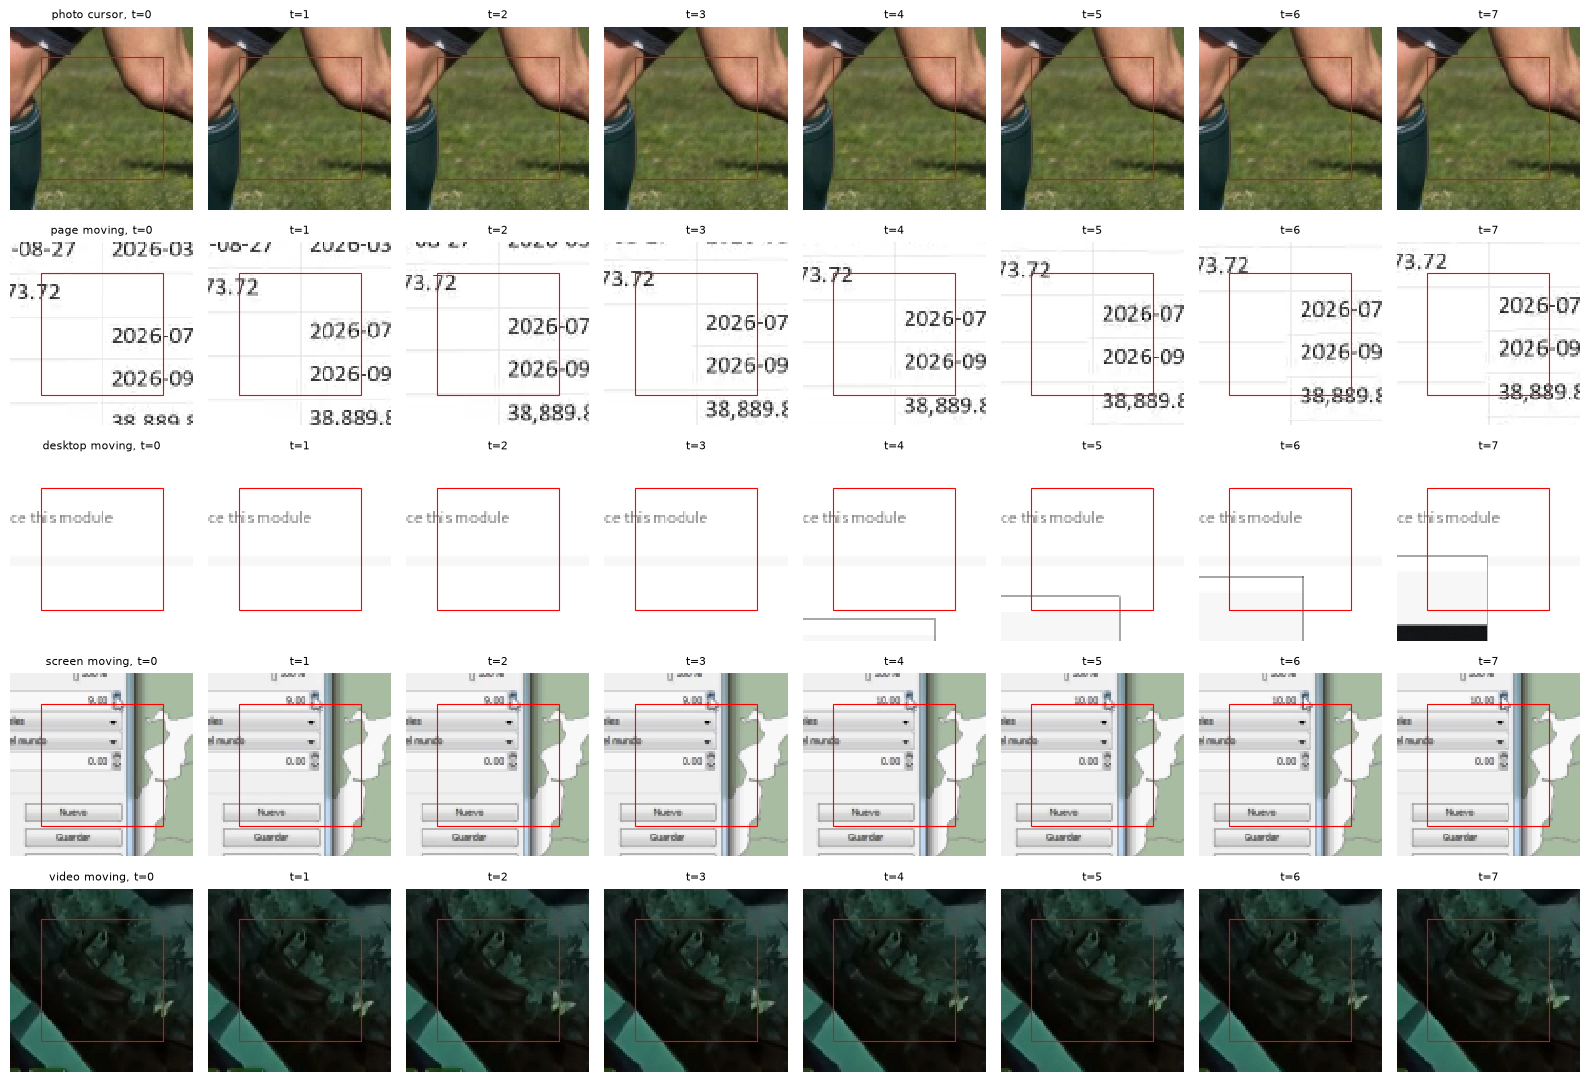

mean luma difference: 5.85 one frame apart, 8.59 two apart


In [9]:
"""Reload from disk, show a few runs, and check their frames are in order."""

manifest = json.loads((OUT_DIR / "manifest.json").read_text(encoding="utf-8"))
frames = np.load(OUT_DIR / manifest["splits"]["train"]["frames"], mmap_mode="r")
print("reloaded", frames.shape, frames.dtype)

train_sources = manifest["splits"]["train"]["sources"]
tag_of = np.array([spot[2] for source in train_sources for spot in source["spots"]])
kind_of_run = np.array([source["kind"] for source in train_sources for _ in source["spots"]])

show_rng = np.random.default_rng(SEED)
picks = [show_rng.choice(np.flatnonzero(mask)) for mask in
         (tag_of == "cursor", (tag_of == "moving") & (kind_of_run == "page"),
          (tag_of == "moving") & (kind_of_run == "desktop"), (tag_of == "moving") & (kind_of_run == "screen"),
          kind_of_run == "video") if mask.any()]
fig, axes = plt.subplots(len(picks), FRAMES_PER_RUN, figsize=(2 * FRAMES_PER_RUN, 2.2 * len(picks)), squeeze=False)
for row, index in enumerate(picks):
    for t in range(FRAMES_PER_RUN):
        ax = axes[row][t]
        ax.imshow(frames[index, t], interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), CORE, CORE, fill=False, color="red", lw=0.8))
        ax.set_title(f"{kind_of_run[index]} {tag_of[index]}, t={t}" if t == 0 else f"t={t}", fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

moving_runs = np.flatnonzero(tag_of != "still")
checked = np.sort(np.random.default_rng(SEED).choice(moving_runs, min(500, len(moving_runs)), replace=False))
sample = core(np.asarray(frames[checked]).reshape(-1, INPUT, INPUT, 3)).reshape(len(checked), FRAMES_PER_RUN, CORE, CORE, 3)
sample = sample.astype(np.float32) @ LUMA
one_apart = np.abs(sample[:, 1:] - sample[:, :-1]).mean()
two_apart = np.abs(sample[:, 2:] - sample[:, :-2]).mean()
print(f"mean luma difference: {one_apart:.2f} one frame apart, {two_apart:.2f} two apart")
assert one_apart < two_apart, "the frames of a run are not in order"

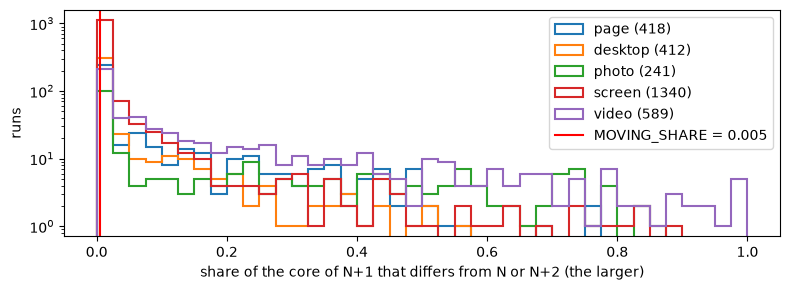

             runs  changed
page          418      48%
desktop       412      28%
photo         241      65%
screen       1340      28%
video         589      80%
events in the train clips: {'cursor': 207, 'popup': 64, 'drag': 56, 'steady': 41, 'wheel': 39, 'flick': 37, 'region': 33}
next: 01_interpolate_dummy.ipynb


In [10]:
"""How much of each run's core differs between the frame N+1 the client makes and the
received frames N and N+2 either side of it."""

t = runs.newest(len(frames), FRAMES_PER_RUN, 2, -1, RECEIVED_EVERY, RECEIVED_EVERY)   # N+2
subset = np.sort(np.random.default_rng(SEED).choice(len(frames), min(3000, len(frames)), replace=False))
share = np.array([max(runs.changed_share(core(frames[i, t[i] - 2:t[i] - 1]), core(frames[i, t[i] - 1:t[i]]))[0],
                      runs.changed_share(core(frames[i, t[i]:t[i] + 1]), core(frames[i, t[i] - 1:t[i]]))[0])
                  for i in subset])

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(0, 1, 41)
for kind in ("page", "desktop", "photo", "screen", "video"):
    chosen = kind_of_run[subset] == kind
    if chosen.any():
        ax.hist(share[chosen], bins=bins, histtype="step", lw=1.5, label=f"{kind} ({chosen.sum()})")
ax.axvline(runs.MOVING_SHARE, color="red", label=f"MOVING_SHARE = {runs.MOVING_SHARE}")
ax.set_yscale("log")
ax.set_xlabel("share of the core of N+1 that differs from N or N+2 (the larger)")
ax.set_ylabel("runs")
ax.legend()
fig.tight_layout()
plt.show()

print(f"{'':10}{'runs':>7}{'changed':>9}")
for kind in ("page", "desktop", "photo", "screen", "video"):
    chosen = kind_of_run[subset] == kind
    if chosen.any():
        print(f"{kind:10}{chosen.sum():7}{(share[chosen] >= runs.MOVING_SHARE).mean():9.0%}")
events = {}
for source in train_sources:
    for event in source.get("events", []):
        events[event] = events.get(event, 0) + 1
print("events in the train clips:", dict(sorted(events.items(), key=lambda item: -item[1])))

print("next: 01_interpolate_dummy.ipynb")